In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport
%matplotlib inline
pd.set_option('display.max_columns',None)

In [10]:
optimized_dtypes = {
    'subject_age':'Int8',
    'location': 'category',
    'subject_race': 'category',
    'subject_sex': 'category',
    'officer_race': 'category',
    'officer_sex': 'category',
    'type': 'category',
    'violation': 'category',
    'outcome': 'category',
    'vehicle_make': 'category',
    'vehicle_model': 'category',
    # Use Pandas' nullable boolean for contraband columns to handle missing values
    'contraband_found': 'boolean',
    'contraband_drugs': 'boolean',
    'contraband_weapons': 'boolean',
    'contraband_other': 'boolean',
    # Standard booleans
    'arrest_made': 'bool',
    'citation_issued': 'bool',
    'contraband_alcohol': 'bool',
    'search_conducted': 'bool',
    'search_person': 'bool',
    'search_vehicle': 'bool'
}

df = pd.read_csv(
    '~/Machine Learning/EDA/Project/stops.csv',       
    dtype=optimized_dtypes, 
    parse_dates=['datetime']
)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2091119 entries, 0 to 2091118
Data columns (total 25 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   location                  category      
 1   lat                       float64       
 2   lng                       float64       
 3   subject_age               Int8          
 4   subject_race              category      
 5   subject_sex               category      
 6   officer_race              category      
 7   officer_sex               category      
 8   officer_years_of_service  float64       
 9   type                      category      
 10  violation                 category      
 11  arrest_made               bool          
 12  citation_issued           bool          
 13  outcome                   category      
 14  contraband_found          boolean       
 15  contraband_drugs          boolean       
 16  contraband_weapons        boolean       
 17  contraba

In [12]:
profile=ProfileReport(df)
profile.to_file('stops.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████████████████████████████████████| 25/25 [00:05<00:00,  4.33it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [13]:
df=df.drop_duplicates()

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2091107 entries, 0 to 2091118
Data columns (total 25 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   location                  category      
 1   lat                       float64       
 2   lng                       float64       
 3   subject_age               Int8          
 4   subject_race              category      
 5   subject_sex               category      
 6   officer_race              category      
 7   officer_sex               category      
 8   officer_years_of_service  float64       
 9   type                      category      
 10  violation                 category      
 11  arrest_made               bool          
 12  citation_issued           bool          
 13  outcome                   category      
 14  contraband_found          boolean       
 15  contraband_drugs          boolean       
 16  contraband_weapons        boolean       
 17  contraband_al

#### Univariate Analysis

In [63]:
df['subject_age'].describe()

count    1464686.0
mean     36.434772
std      13.342165
min           16.0
25%           26.0
50%           33.0
75%           45.0
max          100.0
Name: subject_age, dtype: Float64

In [64]:
df['subject_age'].info()

<class 'pandas.core.series.Series'>
Index: 2091107 entries, 0 to 2091118
Series name: subject_age
Non-Null Count    Dtype
--------------    -----
1464686 non-null  Int8 
dtypes: Int8(1)
memory usage: 19.9 MB


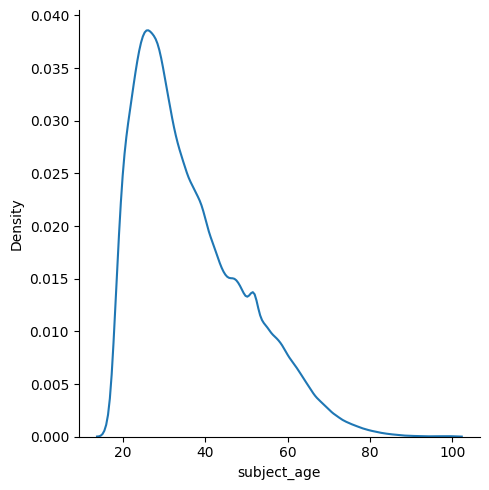

In [65]:
sns.displot(data=df,x='subject_age',kind='kde')

In [66]:
df['subject_age'].skew()

np.float64(0.8797787365820535)

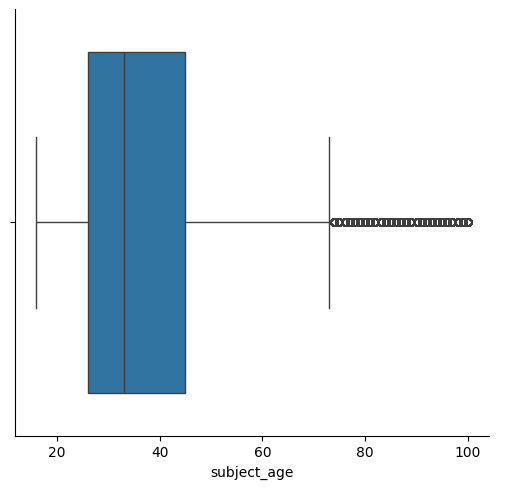

In [67]:
sns.catplot(data=df,x='subject_age',kind='box')

In [61]:
#converting the mistyped ages to nan
df.loc[df['subject_age']<16]=np.nan